<p><a href="https://query.farm/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a></p>

<p><a href="https://query.farm/vgi/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/vgi-logo.png" alt="VGI" width="112"></a></p>

# [EIA Energy Data](https://github.com/Query-farm/vgi-eia)

Explore EIA API v2 routes, facets and frequencies, then retrieve energy observations and legacy series with original dimensions and units.

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Query-farm/vgi-eia/blob/main/notebooks/02_zero_is_an_observation.ipynb)

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Example notes](https://github.com/Query-farm/vgi-eia/blob/main/notebooks/README.md)


## A numeric zero still contributes to observed coverage

**When should an available-month subtotal be displayed?** Six authored monthly responses include numeric zero, positive values, missing, withheld and insignificant markers. We will discover the selected sector, reconcile the legacy-series and explicit-route interfaces, and require a visible minimum number of numeric months before displaying a subtotal.

**Entirely synthetic local API fixtures.** These are not EIA observations or measured Colorado sales. CO/RES-shaped identifiers exercise the real released worker's parsing and pagination contract. The companion server serves exact declared bytes; it performs no analytical transformations. The separate [price-weighting notebook](01_weight_monthly_electricity_prices.ipynb) uses official recordings.

### Set a minimum observed-month requirement

`MIN_OBSERVED_MONTHS` is an integer from 1 to 6. The default **3** and experiment **4** change a local display requirement while all six source rows remain fixed. Numeric zero counts as an observed month. Missing, withheld and insignificant markers do not become numeric zero.

Even when the requirement passes, the value is an **available-month subtotal**, not a complete six-month estimate. No imputation or annualization occurs.

In [1]:
MIN_OBSERVED_MONTHS = 3  # Integer 1–6; experiment 4

In [2]:
import importlib.metadata as packages
import sys

installed = {d.metadata["Name"]: d.version for d in packages.distributions()}
if installed.get("vgi-example-notebooks") != "0.3.35":
    %pip install -q "git+https://github.com/Query-farm/vgi-example-notebooks@v0.3.35"
    if "vgi_notebooks" in sys.modules:
        raise RuntimeError("Restart the kernel, then run all cells.")

from vgi_notebooks import check_runtime  # noqa: E402

check_runtime()
from vgi_notebooks.bootstrap import prepare  # noqa: E402

_companion_directory = prepare("eia")

In [3]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from IPython.display import display
from vgi_notebooks import connect
from vgi_notebooks.presentation import finish, prose, theme
from notebook_support import cleanup, configure_markers

replay, previous_env, run_at, provenance = configure_markers(MIN_OBSERVED_MONTHS)
theme()
session = connect(globals())
Path("artifacts").mkdir(exist_ok=True)
SOURCE = "Source: authored synthetic EIA-shaped fixtures · actual v0.1.0 worker · not measured energy data"

### Connect to the released worker and resolve a facet value

The shared connection starts with an empty temporary SQL-secret directory and disables persistent secrets. The worker receives only the dummy local key and loopback endpoint. The literal release command starts an isolated Python 3.13 worker; no source checkout or transitive overrides are used.

The facet dictionary distinguishes the **RES** and **COM** identifiers. We select the residential fixture and carry that identity into the legacy ID `ELEC.SALES.CO-RES.M` and the explicit route filter. The dictionary supplies identity, not a claim that any values were measured.

In [4]:
%%sql
INSTALL vgi FROM community;
LOAD vgi;
ATTACH 'eia' (TYPE vgi,
 LOCATION 'uvx --python 3.13 --from git+https://github.com/Query-farm/vgi-eia@v0.1.0 vgi-eia-worker');
CREATE TABLE sector_dictionary AS SELECT * FROM eia.main.facet_values('electricity/retail-sales','sectorid');
CREATE TABLE selected_sector AS SELECT id,name FROM sector_dictionary WHERE id='RES';
SELECT id,name,id IN (SELECT id FROM selected_sector) AS selected FROM sector_dictionary ORDER BY id;

,id,name,selected
0,COM,Commercial fixture,False
1,RES,Residential fixture,True


### Read the same six authored records through two interfaces

Both calls request January–June 2024 in pages of three. The legacy function infers frequency and the single measure from its response; the explicit function validates measure, frequency and facet names against metadata. Materialize both results before display so capture does not refetch them.

A full outer join retains missing keys from either route. We compare native period, original value text, parsed value, status, units, frequency and selected sector. The route strings themselves differ by design.

In [5]:
%%sql
CREATE TABLE legacy AS
SELECT * FROM eia.main.series('ELEC.SALES.CO-RES.M',start_period := '2024-01',
 end_period := '2024-06',page_size := 3,max_rows := 0);
CREATE TABLE explicit AS
SELECT * FROM eia.main.observations('electricity/retail-sales','sales','monthly',
 facets_json := '{"stateid":["CO"],"sectorid":["RES"]}',start_period := '2024-01',
 end_period := '2024-06',page_size := 3,max_rows := 0);
CREATE TABLE aligned AS
SELECT coalesce(l.period,e.period) AS period,l.value,l.value_text,l.value_status,l.units,
       l.frequency,l.measure,json_extract_string(l.dimensions_json,'$.sectorid') AS sectorid,
       l.period IS NOT NULL AND e.period IS NOT NULL AS both_present,
       l.value IS NOT DISTINCT FROM e.value AND l.value_text IS NOT DISTINCT FROM e.value_text
         AND l.value_status=e.value_status AND l.units=e.units AND l.frequency=e.frequency
         AND l.measure=e.measure AND l.dimensions_json=e.dimensions_json AS same_observation
FROM legacy l FULL OUTER JOIN explicit e USING(period);
SELECT a.*,s.name AS selected_sector FROM aligned a LEFT JOIN selected_sector s ON a.sectorid=s.id
ORDER BY period;

,period,value,value_text,value_status,units,frequency,measure,sectorid,both_present,same_observation,selected_sector
0,2024-01,0.0,0,numeric,million kilowatt hours,monthly,sales,RES,True,True,Residential fixture
1,2024-02,12.5,12.5,numeric,million kilowatt hours,monthly,sales,RES,True,True,Residential fixture
2,2024-03,NaN,w,withheld,million kilowatt hours,monthly,sales,RES,True,True,Residential fixture
3,2024-04,NaN,None,missing,million kilowatt hours,monthly,sales,RES,True,True,Residential fixture
4,2024-05,NaN,*,insignificant,million kilowatt hours,monthly,sales,RES,True,True,Residential fixture
5,2024-06,18.0,18,numeric,million kilowatt hours,monthly,sales,RES,True,True,Residential fixture


### Keep source markers separate from measured zero

The worker returns numeric zero as `value=0` with status `numeric`. The authored `w`, `null` and `*` entries remain `withheld`, `missing` and `insignificant`, with numeric value NULL. Unknown or nonnumeric values are not placed at zero on the quantity axis. The separate status strip retains all six calendar slots.

In [6]:
%%sql observations <<
SELECT period,value,value_text,value_status FROM aligned ORDER BY period;

,period,value,value_text,value_status
0,2024-01,0.0,0,numeric
1,2024-02,12.5,12.5,numeric
2,2024-03,NaN,w,withheld
3,2024-04,NaN,None,missing
4,2024-05,NaN,*,insignificant
5,2024-06,18.0,18,numeric


The real worker returns **3 numeric months** out of **6**, including **1 numeric zero**. The other source markers retain their distinct statuses. Their numeric NULLs do not establish zero consumption.

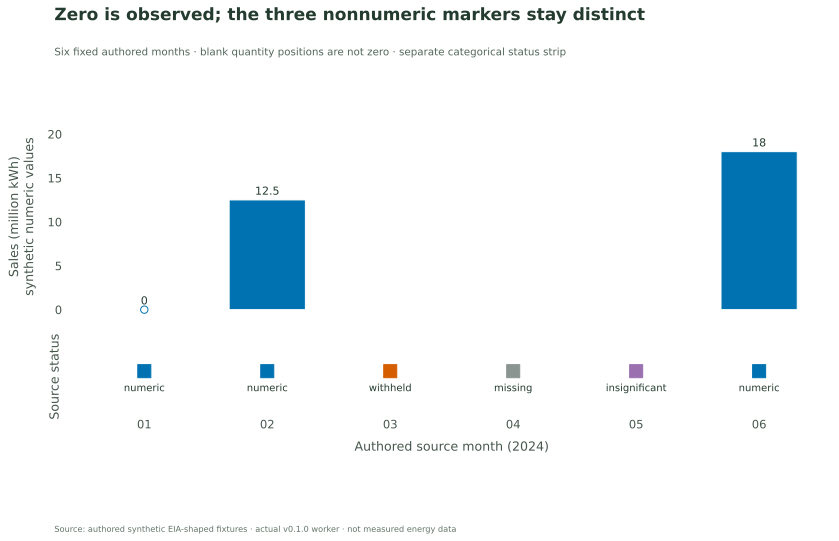

In [7]:
display(observations)
counts = observations.value_status.value_counts()
prose(
    f"The real worker returns **{int(counts.get('numeric', 0))} numeric months** out of **{len(observations)}**, including **{int((observations.value == 0).sum())} numeric zero**. The other source markers retain their distinct statuses. Their numeric NULLs do not establish zero consumption."
)
colors = {
    "numeric": "#0072B2",
    "missing": "#8A9490",
    "withheld": "#D55E00",
    "insignificant": "#9B70AE",
}
fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True, gridspec_kw={"height_ratios": [3, 1]})
x = np.arange(len(observations))
valid = observations.value_status.eq("numeric")
axes[0].bar(x[valid], observations.loc[valid, "value"], color=colors["numeric"], width=0.62)
for index, row in observations[valid].iterrows():
    axes[0].text(index, float(row.value) + 0.6, f"{row.value:g}", ha="center")
    if row.value == 0:
        axes[0].scatter(
            [index], [0], s=55, facecolor="white", edgecolor=colors["numeric"], zorder=3
        )
axes[0].set(ylabel="Sales (million kWh)\nsynthetic numeric values", ylim=(-0.8, 22))
for index, row in observations.iterrows():
    axes[1].scatter(index, 0, s=170, color=colors[row.value_status], marker="s")
    axes[1].text(index, -0.36, row.value_status, ha="center", fontsize=10)
axes[1].set(
    ylim=(-0.7, 0.5), yticks=[], ylabel="Source status", xlabel="Authored source month (2024)"
)
axes[1].set_xticks(x, observations.period.str[5:])
finish(
    fig,
    "Zero is observed; the three nonnumeric markers stay distinct",
    "Six fixed authored months · blank quantity positions are not zero · separate categorical status strip",
    SOURCE,
    name="marker-values",
)

### Apply the requirement without estimating unobserved months

Count numeric months and sum only their values. The zero contributes one observed month and zero to the subtotal. Compare that count with the visible requirement; return NULL when it is not met. The denominator remains all six authored months, regardless of the decision.

This is a demonstration of a declared display policy, not an EIA publication rule or a recommendation for missing-data treatment.

In [8]:
%%sql decision <<
WITH coverage AS (
 SELECT count(*) AS expected_months,count(value) AS observed_months,
        count(*) FILTER(WHERE value_status='numeric' AND value=0) AS zero_months,
        sum(value) AS available_month_subtotal FROM aligned
)
SELECT *,{{MIN_OBSERVED_MONTHS}} AS required_months,
       observed_months>={{MIN_OBSERVED_MONTHS}} AS eligible,
       CASE WHEN observed_months>={{MIN_OBSERVED_MONTHS}} THEN available_month_subtotal END AS displayed_subtotal
FROM coverage;

,expected_months,observed_months,zero_months,available_month_subtotal,required_months,eligible,displayed_subtotal
0,6,3,1,30.5,3,True,30.5


**3 of 6 months** are numeric; the requirement is **3**. **30.5 million kWh available-month subtotal.** The internally observed subtotal remains **30.5 million kWh** in either experiment. It does not include unknown values and cannot be called a complete six-month total.

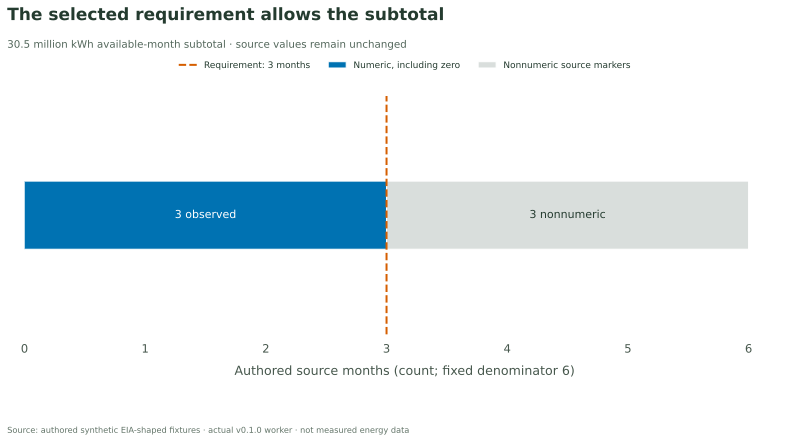

In [9]:
display(decision)
d = decision.iloc[0]
label = (
    f"{d.displayed_subtotal:g} million kWh available-month subtotal"
    if d.eligible
    else "Subtotal withheld by the selected requirement"
)
prose(
    f"**{int(d.observed_months)} of {int(d.expected_months)} months** are numeric; the requirement is **{int(d.required_months)}**. **{label}.** The internally observed subtotal remains **{d.available_month_subtotal:g} million kWh** in either experiment. It does not include unknown values and cannot be called a complete six-month total."
)
fig, ax = plt.subplots(figsize=(12, 6.5))
ax.barh([0], [d.observed_months], color="#0072B2", height=0.4, label="Numeric, including zero")
ax.barh(
    [0],
    [d.expected_months - d.observed_months],
    left=[d.observed_months],
    color="#D9DEDC",
    height=0.4,
    label="Nonnumeric source markers",
)
ax.axvline(
    d.required_months,
    color="#D55E00",
    linewidth=2,
    linestyle="--",
    label=f"Requirement: {int(d.required_months)} months",
)
ax.text(
    d.observed_months / 2,
    0,
    f"{int(d.observed_months)} observed",
    ha="center",
    va="center",
    color="white",
)
ax.text(
    (d.observed_months + d.expected_months) / 2,
    0,
    f"{int(d.expected_months - d.observed_months)} nonnumeric",
    ha="center",
    va="center",
)
ax.set(
    xlim=(0, 6.3),
    ylim=(-0.7, 0.7),
    yticks=[],
    xticks=range(7),
    xlabel="Authored source months (count; fixed denominator 6)",
)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, 1.18), ncol=3, fontsize=9)
finish(
    fig,
    f"The selected requirement {'allows' if d.eligible else 'withholds'} the subtotal",
    label + " · source values remain unchanged",
    SOURCE,
    name=f"coverage-{MIN_OBSERVED_MONTHS}",
)

### Reconcile the interfaces and audit every local request

All six rows and their statuses must agree between the two access paths. Each three-row page must be read once. The request audit contains identifiers only; credentials never appear in saved output.

In [10]:
%%sql checks <<
SELECT 'Six unique months on both routes' AS check_name,
 (SELECT count(*)=6 AND count(DISTINCT period)=6 FROM legacy)
 AND (SELECT count(*)=6 AND count(DISTINCT period)=6 FROM explicit) AS passed
UNION ALL SELECT 'Full outer reconciliation',count(*)=6 AND bool_and(both_present AND same_observation) FROM aligned
UNION ALL SELECT 'Selected dictionary identity',count(*)=6 AND bool_and(a.sectorid=s.id) FROM aligned a JOIN selected_sector s ON a.sectorid=s.id
UNION ALL SELECT 'Frequency and units',bool_and(frequency='monthly' AND measure='sales' AND units='million kilowatt hours') FROM aligned
UNION ALL SELECT 'Three numeric and three distinct nonnumeric statuses',count(*) FILTER(WHERE value_status='numeric')=3 AND count(DISTINCT value_status)=4 FROM aligned
UNION ALL SELECT 'Numeric zero retained',count(*) FILTER(WHERE value_status='numeric' AND value=0)=1 FROM aligned
UNION ALL SELECT 'NULL agrees with nonnumeric status',bool_and((value IS NULL)=(value_status<>'numeric')) FROM aligned
UNION ALL SELECT 'Known authored numeric subtotal',abs(sum(value)-30.5)<1e-10 FROM aligned;

In [11]:
display(checks)
assert checks.passed.fillna(False).all()
assert sorted(replay.requests) == sorted(
    ["sectors", "metadata", "legacy-0", "legacy-3", "explicit-0", "explicit-3"]
), replay.requests
prose(
    f"All **{len(checks)} SQL checks** pass; the fixture served exactly **{len(replay.requests)} requests**. The displayed subtotal is controlled only by the minimum count, while the worker's numeric values and source statuses stay fixed."
)
Path("artifacts/analysis-02.json").write_text(
    json.dumps(
        {
            "minimum": MIN_OBSERVED_MONTHS,
            "observations": observations.to_dict("records"),
            "decision": decision.to_dict("records"),
            "checks": checks.to_dict("records"),
            "requests": replay.requests,
        },
        indent=2,
        default=str,
    )
    + "\n"
)

,check_name,passed
0,Six unique months on both routes,True
1,Full outer reconciliation,True
2,Selected dictionary identity,True
3,Frequency and units,True
4,Three numeric and three distinct nonnumeric st...,True
5,Numeric zero retained,True
6,NULL agrees with nonnumeric status,True
7,Known authored numeric subtotal,True


All **8 SQL checks** pass; the fixture served exactly **6 requests**. The displayed subtotal is controlled only by the minimum count, while the worker's numeric values and source statuses stay fixed.

1840

### Experiment: require four observed months

Change **MIN_OBSERVED_MONTHS from 3 to 4**, then execute a separate copy. The observed count stays 3, including the zero. The available-month subtotal stays 30.5, the first chart stays identical and the request/route audits remain unchanged. Only eligibility, displayed subtotal and the requirement line change.

No status is rewritten and no unknown quantity is estimated. The [fixture guide](marker_fixtures/README.md) documents the authored inputs; the separate official-recording notebook answers the price-weighting question.

In [12]:
assert con.execute("SELECT * FROM duckdb_secrets()").fetchall() == []
session.close()
cleanup(replay, previous_env)
plt.close("all")

<a href="https://query.farm/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Worker repository: vgi-eia](https://github.com/Query-farm/vgi-eia)
